# Resultados da execução final (TCC 2)

Este notebook **não treina nada**. Ele lê os `.json` da execução final em `results/final/`, um por execução, declarados nos 14 arquivos de [`configs/final/`](../configs/final/), e gera as tabelas e as figuras de cada capítulo do TCC 2.

A execução foi feita com `python -m parallel_pinns.cli.run_all "configs/final/*.yaml"`. Os manifestos (`results/final/manifesto_<experimento>.json`) registram o commit, as versões e a plataforma.

Convenções:
- erros resumidos em escala log10: média geométrica e fator de dispersão $10^{s}$, em que $s$ é o desvio padrão de $\log_{10} E$;
- comparações pareadas por semente: razão geométrica A/B, IC 90%, Hodges–Lehmann (HL) e Wilcoxon bilateral;
- **falha** de uma execução: $E_{L2} > 0{,}1$ ou, em P2, $E_n > 0{,}5$ (definição fixada antes do teste confirmatório);
- as figuras vão para `notebooks/figuras/` em PDF, prontas para o LaTeX.

In [1]:
import json
import sys
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))          # dispensa a instalacao do pacote

import matplotlib.pyplot as plt
import numpy as np

from parallel_pinns.analysis import time_to_solution
from parallel_pinns.statistics import comparar_razao, desfecho_h2, resumo_log, tost_log
from parallel_pinns.tracking import arquivo_resultado, carregar_config, carregar_resultados
from parallel_pinns.utils.metrics import ajustar_amdahl, amdahl

RESULTADOS = RAIZ / "results"
FIGURAS = RAIZ / "notebooks" / "figuras"
FIGURAS.mkdir(exist_ok=True)

CFG = {c.stem: carregar_config(c) for c in sorted((RAIZ / "configs" / "final").glob("*.yaml"))}
R = {k: carregar_resultados(c, resultados=RESULTADOS) for k, c in CFG.items()}

PROBLEMAS = [("L0", None), ("P0", None), ("P1", None), ("P2", 5), ("P2", 7), ("P2", 11), ("P2", 13)]
rotulo = lambda prob, n: f"{prob}({n})" if n else prob


def sel(experimento, **filtro):
    # Resultados de um experimento cujas opcoes batem com o filtro, na ordem das sementes (pareados entre si)
    return [r for t, r in R[experimento] if all(t.get(k) == v for k, v in filtro.items())]


def met(rs, chave="L2"):
    return [r["metricas"][chave] for r in rs]


def falha(m):
    return m["L2"] > 0.1 or m.get("E_n", 0) > 0.5


def geo(valores):
    g, fator, _ = resumo_log(valores)
    return f"{g:.2e} ×/ {fator:.1f}"


def salvar(fig, nome):
    fig.savefig(FIGURAS / f"{nome}.pdf", bbox_inches="tight")


arquivos = {arquivo_resultado(c["tipo"], t) for k, c in CFG.items() for t, _ in R[k]}
print(f"{len(CFG)} experimentos, {sum(len(v) for v in R.values())} execuções declaradas, {len(arquivos)} sem repetição")

14 experimentos, 620 execuções declaradas, 570 sem repetição


## Proveniência

Todos os experimentos têm de vir do mesmo commit, sem alterações locais no código ou nas configurações.

In [2]:
manifestos = {k: json.loads((RESULTADOS / "final" / f"manifesto_{c['nome']}.json").read_text(encoding="utf-8"))
              for k, c in CFG.items()}
commits = {m["commit"] for m in manifestos.values()}
assert len(commits) == 1 and not any(m["alteracoes_nao_commitadas"] for m in manifestos.values())
m = next(iter(manifestos.values()))
print("commit:", commits.pop())
print("versões:", m["versoes"])
print("plataforma:", m["plataforma"])
print("início:", min(m["inicio"] for m in manifestos.values()), "| fim:", max(m["fim"] for m in manifestos.values()))

commit: 540f1a4b3c5fd3b71b41947001489e9ed9330266
versões: {'parallel_pinns': '0.2.0.dev0', 'python': '3.11.5', 'torch': '2.13.0+cu132', 'numpy': '2.4.6', 'scipy': '1.16.3'}
plataforma: {'sistema': 'Windows-10-10.0.19045-SP0', 'processador': 'Intel64 Family 6 Model 63 Stepping 2, GenuineIntel', 'nucleos_logicos': 12, 'gpu': 'NVIDIA GeForce GTX 1660'}
início: 2026-11-25T01:29:34-03:00 | fim: 2026-11-25T19:42:59-03:00


# 1. Verificação

## 1.1 Escolha de $\lambda_I$ e $\lambda_{BC}$

Os valores foram fixados na versão exploratória ($\lambda_I = 0{,}03$, $\lambda_{BC} = 1$). Aqui eles são conferidos com sementes separadas (10 a 12), em P2(11), pelo critério fixado antes: o menor $E_{L2}$ geométrico.

In [3]:
for experimento, chave, fixado in [("escolha_lam_i", "lam_i", 0.03), ("escolha_lam_bc", "lam_bc", 1.0)]:
    valores = sorted({t[chave] for t, _ in R[experimento]})
    geom = {v: resumo_log(met(sel(experimento, **{chave: v})))[0] for v in valores}
    escolhido = min(geom, key=geom.get)
    print(f"{chave}: " + " | ".join(f"{v}: {g:.2e}" for v, g in geom.items())
          + f"  -> menor E_L2: {escolhido} (fixado: {fixado}; {'confere' if escolhido == fixado else 'NÃO confere'})")

lam_i: 0.03: 1.03e-02 | 0.1: 1.05e-02 | 0.3: 2.78e-02 | 1.0: 2.20e-02  -> menor E_L2: 0.03 (fixado: 0.03; confere)
lam_bc: 0.1: 3.16e-02 | 0.3: 1.65e-02 | 1.0: 8.57e-03 | 3.0: 3.37e-02  -> menor E_L2: 1.0 (fixado: 1.0; confere)


## 1.2 Formulação do contorno (monolítica, P2(11), GPU)

Contorno fraco (o do núcleo), exato com $D$ produto e transfinito. As razões são em relação ao contorno fraco, pareadas por semente.

In [4]:
fraco = sel("sens_contorno", contorno="fraco")
print(f"{'contorno':>12} {'E_L2':>18} {'E_H1':>18} {'E_n':>18} {'falhas':>7} {'razão E_L2 / fraco':>19} {'HL':>6} {'Wilcoxon p':>11}")
for c in ("fraco", "exato", "transfinito"):
    rs = sel("sens_contorno", contorno=c)
    linha = f"{c:>12} {geo(met(rs)):>18} {geo(met(rs, 'H1')):>18} {geo(met(rs, 'E_n')):>18} {sum(falha(r['metricas']) for r in rs):>7}"
    if c != "fraco":
        k = comparar_razao(met(rs), met(fraco))
        linha += f" {k['razao']:19.2f} {k['hodges_lehmann']:6.2f} {k['p_wilcoxon']:11.3g}"
    print(linha)

    contorno               E_L2               E_H1                E_n  falhas  razão E_L2 / fraco     HL  Wilcoxon p
       fraco    8.15e-03 ×/ 2.7    2.88e-02 ×/ 2.4    1.18e-03 ×/ 2.7       0
       exato    4.57e-01 ×/ 1.8    9.14e-01 ×/ 1.2    7.22e-01 ×/ 1.2      10               56.12  62.79     0.00195
 transfinito    2.44e-02 ×/ 4.6    4.67e-02 ×/ 4.0    5.33e-03 ×/ 5.9       2                3.00   2.20       0.193


# 2. RQ1: tempo, speedup e lei de Amdahl

Cada medição rodou **sozinha** na máquina, com um processo por núcleo físico (afinidade fixa), 500 iterações de Adam e 10 passos de L-BFGS. O tempo por iteração é o tempo de treino dividido pelas iterações. A referência $p = 1$ também foi medida com os outros 5 núcleos ocupados por laços vazios: com todos os núcleos ativos, o processador não sobe ao turbo de um núcleo só, e o speedup fica livre desse efeito.

## 2.1 DDP

   N_f   p  ms/iteração   S(p)  eficiência  S(p), ref. com carga
  2400   1         70.1   1.00        1.00                  0.99
  2400   2         42.1   1.67        0.83                  1.66
  2400   3         43.0   1.63        0.54                  1.62
  2400   4         36.2   1.94        0.48                  1.93
  2400   6         45.5   1.54        0.26                  1.53
       p = 1 com carga: 0.99 vez o tempo sozinho
       Amdahl,   ref. sozinha: f = 0.571 | 1 - f = 0.429 | S(∞) = 2.3
       Amdahl, ref. com carga: f = 0.566 | 1 - f = 0.434 | S(∞) = 2.3

  4800   1        125.3   1.00        1.00                  1.05
  4800   2         94.0   1.33        0.67                  1.39
  4800   3         71.8   1.74        0.58                  1.82
  4800   4         65.4   1.92        0.48                  2.00
  4800   6         70.3   1.78        0.30                  1.86
       p = 1 com carga: 1.05 vez o tempo sozinho
       Amdahl,   ref. sozinha: f = 0.581 | 1 -

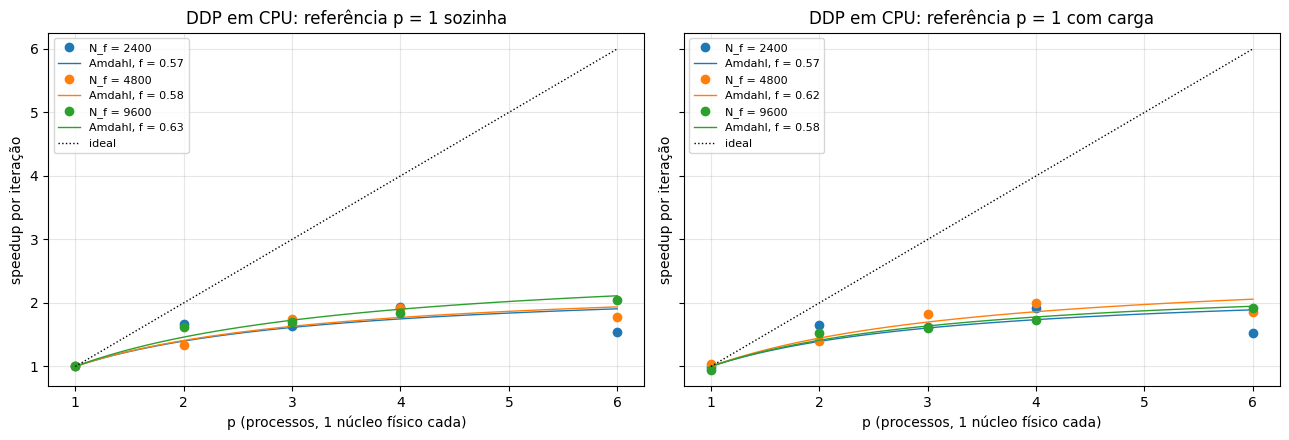

In [5]:
def t_iter(r):
    return r["tempo"] / r["hist"]["it_final"]


P_TEMPO, NF_TEMPO = [1, 2, 3, 4, 6], [2400, 4800, 9600]
tempo = {(t["N_f"], t["p"], bool(t.get("carga"))): t_iter(r) for t, r in R["tempo_ddp"]}
f_ddp = {}
print(f"{'N_f':>6} {'p':>3} {'ms/iteração':>12} {'S(p)':>6} {'eficiência':>11} {'S(p), ref. com carga':>21}")
for N_f in NF_TEMPO:
    S = {p: tempo[(N_f, 1, False)] / tempo[(N_f, p, False)] for p in P_TEMPO}
    S_c = {p: tempo[(N_f, 1, True)] / tempo[(N_f, p, False)] for p in P_TEMPO}
    for p in P_TEMPO:
        print(f"{N_f:>6} {p:>3} {1000 * tempo[(N_f, p, False)]:12.1f} {S[p]:6.2f} {S[p] / p:11.2f} {S_c[p]:21.2f}")
    f_ddp[N_f] = ajustar_amdahl(S), ajustar_amdahl(S_c)
    print(f"{'':>6} p = 1 com carga: {tempo[(N_f, 1, True)] / tempo[(N_f, 1, False)]:.2f} vez o tempo sozinho")
    for rot, f in zip(("ref. sozinha", "ref. com carga"), f_ddp[N_f]):
        print(f"{'':>6} Amdahl, {rot:>14}: f = {f:.3f} | 1 - f = {1 - f:.3f} | S(∞) = {1 / (1 - f) if f < 1 else float('inf'):.1f}")
    print()

pp = np.linspace(1, 6, 100)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for a, (i, carga, titulo) in zip(ax, [(0, False, "referência p = 1 sozinha"), (1, True, "referência p = 1 com carga")]):
    for N_f, cor in zip(NF_TEMPO, ["tab:blue", "tab:orange", "tab:green"]):
        a.plot(P_TEMPO, [tempo[(N_f, 1, carga)] / tempo[(N_f, p, False)] for p in P_TEMPO], "o", color=cor, label=f"N_f = {N_f}")
        a.plot(pp, amdahl(pp, f_ddp[N_f][i]), "-", color=cor, lw=1, label=f"Amdahl, f = {f_ddp[N_f][i]:.2f}")
    a.plot(pp, pp, "k:", lw=1, label="ideal")
    a.set(xlabel="p (processos, 1 núcleo físico cada)", ylabel="speedup por iteração", title=f"DDP em CPU: {titulo}")
    a.legend(fontsize=8)
    a.grid(True, alpha=.3)
plt.tight_layout()
salvar(fig, "rq1_speedup_ddp")
plt.show()

## 2.2 XPINN distribuído (replicação de parâmetros)

In [6]:
tempo_x = {(t["M"], t["N_f"], t["p"]): t_iter(r) for t, r in R["tempo_xpinn_distribuido"]}
print(f"{'M':>2} {'N_f':>6} {'p':>3} {'ms/iteração':>12} {'S(p)':>6} {'eficiência':>11}")
f_x = {}
for M in (2, 4):
    for N_f in (2000, 8000):
        S = {p: tempo_x[(M, N_f, 1)] / tempo_x[(M, N_f, p)] for p in (1, 2, 4)}
        for p in (1, 2, 4):
            print(f"{M:>2} {N_f:>6} {p:>3} {1000 * tempo_x[(M, N_f, p)]:12.1f} {S[p]:6.2f} {S[p] / p:11.2f}")
        f_x[(M, N_f)] = ajustar_amdahl(S)
        print(f"{'':>12} Amdahl: f = {f_x[(M, N_f)]:.3f}")

 M    N_f   p  ms/iteração   S(p)  eficiência
 2   2000   1         38.6   1.00        1.00
 2   2000   2         35.7   1.08        0.54
 2   2000   4         37.2   1.04        0.26
             Amdahl: f = 0.080
 2   8000   1         85.3   1.00        1.00
 2   8000   2         63.6   1.34        0.67
 2   8000   4         58.2   1.47        0.37
             Amdahl: f = 0.450
 4   2000   1         37.6   1.00        1.00
 4   2000   2         33.9   1.11        0.55
 4   2000   4         33.5   1.12        0.28
             Amdahl: f = 0.160
 4   8000   1         58.7   1.00        1.00
 4   8000   2         46.4   1.27        0.63
 4   8000   4         46.3   1.27        0.32
             Amdahl: f = 0.324


## 2.3 Custo por ponto de colocação

Tempo por iteração de **um processo** ($p = 1$) em função de $N_f$: o coeficiente angular é o custo de cada ponto de colocação por iteração, e o intercepto, o custo fixo (contorno, interface, otimizador). A monolítica usa $N_b = 480$ e o XPINN, $N_b = 400$.

           arquitetura  custo por ponto (µs/iteração)  custo fixo (ms/iteração)
            monolítica                          28.96                      -5.1
           XPINN M = 2                           7.79                      23.0
           XPINN M = 4                           3.52                      30.5


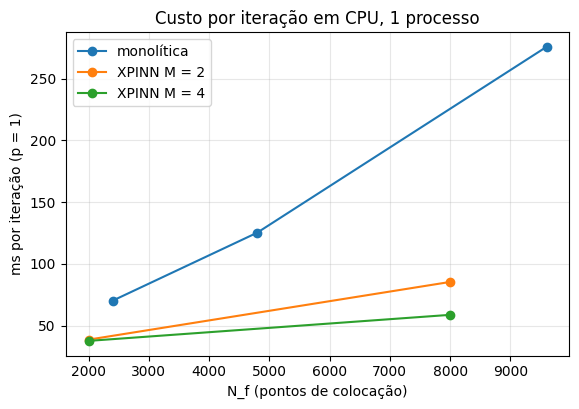

In [7]:
fig, ax = plt.subplots(figsize=(6.5, 4.2))
print(f"{'arquitetura':>22} {'custo por ponto (µs/iteração)':>30} {'custo fixo (ms/iteração)':>25}")
series = [("monolítica", NF_TEMPO, [tempo[(N_f, 1, False)] for N_f in NF_TEMPO]),
          *[(f"XPINN M = {M}", [2000, 8000], [tempo_x[(M, N_f, 1)] for N_f in (2000, 8000)]) for M in (2, 4)]]
for nome, nfs, ts in series:
    b, a0 = np.polyfit(nfs, ts, 1)
    print(f"{nome:>22} {1e6 * b:30.2f} {1e3 * a0:25.1f}")
    ax.plot(nfs, 1000 * np.array(ts), "o-", label=nome)
ax.set(xlabel="N_f (pontos de colocação)", ylabel="ms por iteração (p = 1)", title="Custo por iteração em CPU, 1 processo")
ax.grid(True, alpha=.3)
ax.legend()
salvar(fig, "rq1_custo_por_ponto")
plt.show()

# 3. Núcleo: as quatro arquiteturas nos sete problemas

Monolítica sequencial ($p = 1$, a referência), DDP $p = 4$, XPINN iso-parâmetro $M = 2$ e $M = 4$, todas em CPU com 1 thread, contorno fraco, 5000 iterações, sementes 0 a 9. As razões são pareadas por semente contra a monolítica.

Os tempos destas execuções **não** entram em contas de speedup: elas rodaram ao mesmo tempo que outras.

In [8]:
def arquiteturas(prob, n):
    return {"monolítica": sel("nucleo_ddp", problema=prob, n=n, p=1),
            "DDP p = 4": sel("nucleo_ddp", problema=prob, n=n, p=4),
            "XPINN M = 2": sel("nucleo_xpinn", problema=prob, n=n, M=2),
            "XPINN M = 4": sel("nucleo_xpinn", problema=prob, n=n, M=4)}


print(f"{'problema':>8} {'arquitetura':>12} {'E_L2':>18} {'E_H1':>18} {'E_n':>18} {'falhas':>7} "
      f"{'razão / mono':>13} {'HL':>6} {'pior em':>8} {'Wilcoxon p':>11}")
nucleo = {}
for prob, n in PROBLEMAS:
    arqs = nucleo[rotulo(prob, n)] = arquiteturas(prob, n)
    mono = arqs["monolítica"]
    for nome, rs in arqs.items():
        e_n = geo(met(rs, "E_n")) if prob == "P2" else "-"
        linha = (f"{rotulo(prob, n):>8} {nome:>12} {geo(met(rs)):>18} {geo(met(rs, 'H1')):>18} {e_n:>18} "
                 f"{sum(falha(r['metricas']) for r in rs):>7}")
        if nome != "monolítica":
            k = comparar_razao(met(rs), met(mono))
            linha += f" {k['razao']:13.2f} {k['hodges_lehmann']:6.2f} {k['pior_em']:>5}/{k['n']} {k['p_wilcoxon']:11.3g}"
        print(linha)
    print()

problema  arquitetura               E_L2               E_H1                E_n  falhas  razão / mono     HL  pior em  Wilcoxon p
      L0   monolítica    3.78e-03 ×/ 1.3    1.03e-02 ×/ 1.3                  -       0
      L0    DDP p = 4    3.88e-03 ×/ 1.3    1.07e-02 ×/ 1.3                  -       0          1.03   1.04     6/10       0.625
      L0  XPINN M = 2    3.97e-03 ×/ 1.2    1.21e-02 ×/ 1.2                  -       0          1.05   1.08     6/10       0.557
      L0  XPINN M = 4    1.55e-01 ×/ 1.1    3.09e-01 ×/ 1.1                  -      10         41.18  40.36    10/10     0.00195

      P0   monolítica    2.32e-04 ×/ 1.4    1.01e-03 ×/ 1.4                  -       0
      P0    DDP p = 4    2.41e-04 ×/ 1.4    1.03e-03 ×/ 1.4                  -       0          1.04   1.03     7/10       0.193
      P0  XPINN M = 2    3.79e-04 ×/ 1.3    1.61e-03 ×/ 1.2                  -       0          1.63   1.60     9/10     0.00391
      P0  XPINN M = 4    8.81e-04 ×/ 1.2    4.89e-0

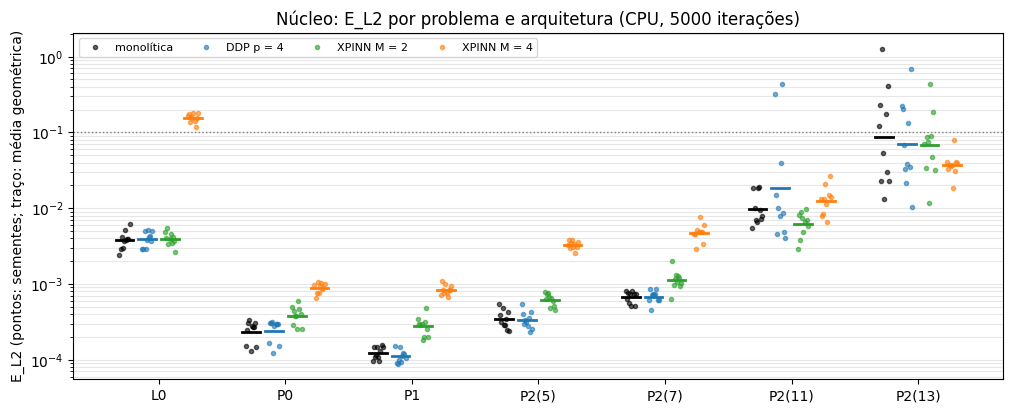

In [9]:
cores = {"monolítica": "k", "DDP p = 4": "tab:blue", "XPINN M = 2": "tab:green", "XPINN M = 4": "tab:orange"}
fig, ax = plt.subplots(figsize=(12, 4.5))
for i, (rot, arqs) in enumerate(nucleo.items()):
    for j, (nome, rs) in enumerate(arqs.items()):
        x = i + (j - 1.5) * 0.18
        ax.semilogy(np.full(len(rs), x) + np.linspace(-0.04, 0.04, len(rs)), met(rs), ".", color=cores[nome], alpha=.6,
                    label=nome if i == 0 else None)
        ax.semilogy([x - 0.07, x + 0.07], [resumo_log(met(rs))[0]] * 2, "-", color=cores[nome], lw=2)
ax.axhline(0.1, color="gray", ls=":", lw=1)
ax.set_xticks(range(len(nucleo)), list(nucleo))
ax.set(ylabel="E_L2 (pontos: sementes; traço: média geométrica)", title="Núcleo: E_L2 por problema e arquitetura (CPU, 5000 iterações)")
ax.grid(True, which="both", axis="y", alpha=.3)
ax.legend(fontsize=8, ncol=4)
salvar(fig, "nucleo_erro_l2")
plt.show()

## 3.1 Convergência ao longo do treino

Mediana entre as sementes de $E_{L2}$ (e de $E_n$ em P2) em função da iteração. O eixo é a iteração, e não o tempo, porque estas execuções rodaram em paralelo com outras.

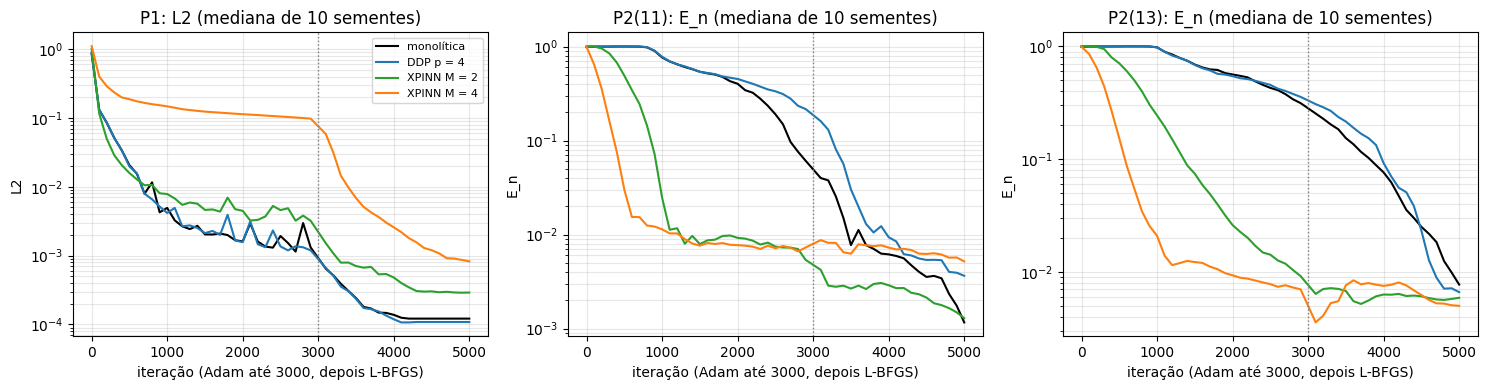

In [10]:
def curva(rs, chave):
    its = rs[0]["hist"]["aval_it"]
    valores = np.array([r["hist"][chave][:len(its)] for r in rs if len(r["hist"][chave]) >= len(its)])
    return its, np.median(valores, axis=0)


casos = [("P1", None, "L2"), ("P2", 11, "E_n"), ("P2", 13, "E_n")]
fig, ax = plt.subplots(1, len(casos), figsize=(15, 4))
for a, (prob, n, chave) in zip(ax, casos):
    for nome, rs in nucleo[rotulo(prob, n)].items():
        a.semilogy(*curva(rs, chave), color=cores[nome], label=nome)
    a.axvline(3000, color="gray", ls=":", lw=1)
    a.set(title=f"{rotulo(prob, n)}: {chave} (mediana de 10 sementes)", xlabel="iteração (Adam até 3000, depois L-BFGS)", ylabel=chave)
    a.grid(True, which="both", alpha=.3)
ax[0].legend(fontsize=8)
plt.tight_layout()
salvar(fig, "nucleo_convergencia")
plt.show()

# 4. H1: o paralelismo preserva a acurácia?

## 4.1 DDP (P1, 20 sementes)

TOST pareado em log10 com margem $[0{,}8;\ 1{,}25]$, fixada antes, e Bonferroni para os dois testes ($p < 0{,}025$ em cada um).

In [11]:
seq = met(sel("h1_ddp_tost", p=1))
print(f"{'':>8} {'razão geom.':>11} {'IC 90%':>16} {'p TOST':>9} {'equivalente':>12} {'HL':>6} {'Wilcoxon p':>11}")
for p in (2, 4):
    par = met(sel("h1_ddp_tost", p=p))
    razao, (lo, hi), p_tost = tost_log(par, seq)
    k = comparar_razao(par, seq)
    print(f"{'p = ' + str(p):>8} {razao:11.3f} {f'[{lo:.3f}; {hi:.3f}]':>16} {p_tost:9.2e} {'sim' if p_tost < 0.025 else 'não':>12} "
          f"{k['hodges_lehmann']:6.3f} {k['p_wilcoxon']:11.3g}")

print("\nDDP p = 4 contra p = 1 no núcleo (10 sementes por problema, indicação):")
for rot, arqs in nucleo.items():
    razao, (lo, hi), p_tost = tost_log(met(arqs["DDP p = 4"]), met(arqs["monolítica"]))
    print(f"{rot:>8}: razão {razao:.3f}, IC 90% [{lo:.3f}; {hi:.3f}], p TOST = {p_tost:.2e}")

         razão geom.           IC 90%    p TOST  equivalente     HL  Wilcoxon p
   p = 2       0.858   [0.675; 1.092]  3.10e-01          não  0.932       0.202
   p = 4       0.800   [0.634; 1.009]  4.99e-01          não  0.899     0.00944

DDP p = 4 contra p = 1 no núcleo (10 sementes por problema, indicação):
      L0: razão 1.027, IC 90% [0.960; 1.099], p TOST = 2.41e-04
      P0: razão 1.037, IC 90% [0.990; 1.086], p TOST = 2.03e-05
      P1: razão 0.898, IC 90% [0.770; 1.048], p TOST = 1.01e-01
   P2(5): razão 0.976, IC 90% [0.907; 1.049], p TOST = 3.68e-04
   P2(7): razão 1.011, IC 90% [0.857; 1.193], p TOST = 2.16e-02
  P2(11): razão 1.887, IC 90% [0.726; 4.903], p TOST = 7.75e-01
  P2(13): razão 0.789, IC 90% [0.352; 1.767], p TOST = 5.12e-01


## 4.2 Ordem das somas: o sequencial em `float64`

Com os mesmos pontos e pesos iniciais, o `float64` mede quanto da diferença entre execuções vem só do arredondamento do `float32`. Se o DDP fica tão perto do sequencial quanto o próprio sequencial fica do `float64`, a diferença do DDP é ruído de arredondamento.

In [12]:
seq64 = met(sel("h1_ordem_somas"))
p4 = met(sel("h1_ddp_tost", p=4))
for rot, a, b in [("float32 / float64 (sequencial)", seq, seq64),
                  ("DDP p=4 / sequencial float64", p4, seq64),
                  ("DDP p=4 / sequencial float32", p4, seq)]:
    k = comparar_razao(a, b)
    print(f"{rot:>32}: razão {k['razao']:.3f} | IC 90% [{k['ic90'][0]:.3f}; {k['ic90'][1]:.3f}] | "
          f"HL {k['hodges_lehmann']:.3f} | Wilcoxon p = {k['p_wilcoxon']:.3g}")
dispersao = lambda a, b: 10 ** np.std(np.log10(a) - np.log10(b), ddof=1)
print(f"\nfator de dispersão das razões por semente: float32/float64 {dispersao(seq, seq64):.2f} | "
      f"DDP/float32 {dispersao(p4, seq):.2f}")

  float32 / float64 (sequencial): razão 1.373 | IC 90% [1.105; 1.706] | HL 1.226 | Wilcoxon p = 0.000105
    DDP p=4 / sequencial float64: razão 1.098 | IC 90% [1.033; 1.168] | HL 1.081 | Wilcoxon p = 0.0192
    DDP p=4 / sequencial float32: razão 0.800 | IC 90% [0.634; 1.009] | HL 0.899 | Wilcoxon p = 0.00944

fator de dispersão das razões por semente: float32/float64 1.75 | DDP/float32 1.82


## 4.3 XPINN distribuído ($M = 2$, 4 processos, contra o XPINN sequencial)

In [13]:
xs, xd = met(sel("h1_xpinn_distribuido", p=1)), met(sel("h1_xpinn_distribuido", p=4))
razao, (lo, hi), p_tost = tost_log(xd, xs)
k = comparar_razao(xd, xs)
print(f"XPINN distribuído / sequencial: razão {razao:.3f}, IC 90% [{lo:.3f}; {hi:.3f}], p TOST = {p_tost:.2e} "
      f"({'equivalente' if p_tost < 0.05 else 'equivalência não demonstrada'}), HL {k['hodges_lehmann']:.3f}, Wilcoxon p = {k['p_wilcoxon']:.3g}")

XPINN distribuído / sequencial: razão 1.011, IC 90% [0.962; 1.062], p TOST = 1.26e-05 (equivalente), HL 1.013, Wilcoxon p = 0.846


# 5. RQ3: o limiar da monolítica

P2($n$) com $n$ de 11 a 31, cerca de 8 pontos de colocação por comprimento de onda ($N_f \propto n^2$) e grade de avaliação com $4n + 3$ pontos por direção, 10 sementes, na GPU. O controle com $N_f = 2000$ fixo ($n = 21$ e 31, 3 sementes) separa a dificuldade espectral da falta de pontos.

  n    N_f               E_L2                E_n                E_1  falhas  TTS E_n<0,1 (s)
 11   2000    8.15e-03 ×/ 2.7    1.18e-03 ×/ 2.7    2.71e-03 ×/ 4.0    0/10       167 (10/10)
 15   3719    1.69e-01 ×/ 2.9   2.83e-02 ×/ 14.3    1.06e-01 ×/ 4.5    7/10       230 (6/10)
 21   7289    9.82e-01 ×/ 1.0    8.85e-01 ×/ 1.3    9.82e-01 ×/ 1.0   10/10            nunca
 25  10331    9.95e-01 ×/ 1.0    1.00e+00 ×/ 1.0    9.95e-01 ×/ 1.0   10/10            nunca
 31  15884    9.97e-01 ×/ 1.0    1.00e+00 ×/ 1.0    9.97e-01 ×/ 1.0   10/10            nunca

Controle de subamostragem (sementes 0 a 2): N_f = 2000 fixo / N_f escalado
n = 21: E_L2 1.05e+00 ×/ 1.1 contra 9.85e-01 ×/ 1.0 | E_n 5.87e-01 ×/ 1.8 contra 1.00e+00 ×/ 1.0 | falhas 3/3 contra 3/3
n = 31: E_L2 9.96e-01 ×/ 1.0 contra 9.97e-01 ×/ 1.0 | E_n 1.00e+00 ×/ 1.0 contra 1.00e+00 ×/ 1.0 | falhas 3/3 contra 3/3


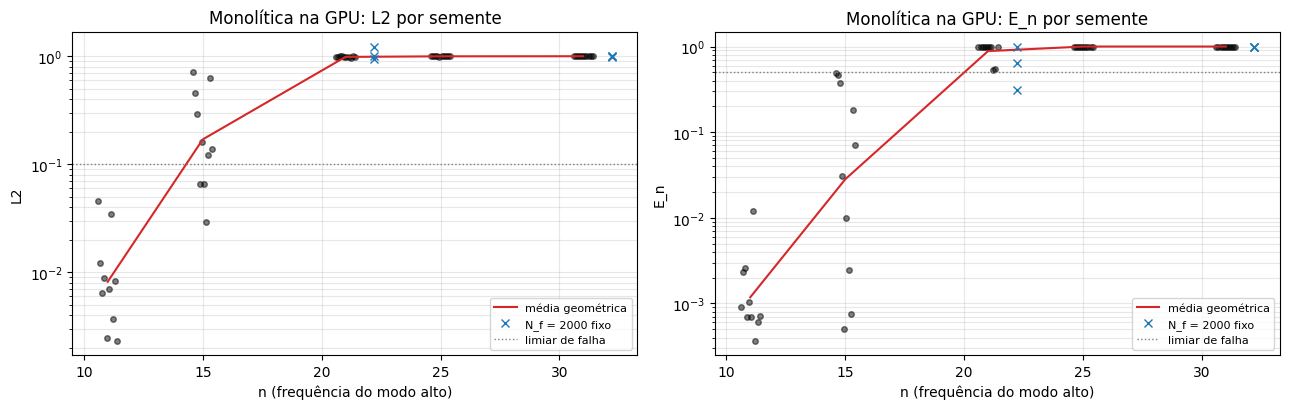

In [14]:
VALORES_N = [11, 15, 21, 25, 31]
print(f"{'n':>3} {'N_f':>6} {'E_L2':>18} {'E_n':>18} {'E_1':>18} {'falhas':>7} {'TTS E_n<0,1 (s)':>16}")
varredura = {}
for n in VALORES_N:
    rs = varredura[n] = sel("rq3_varredura", n=n)
    tts = [time_to_solution(r["hist"], "E_n", 0.1) for r in rs]
    ok = [t for t in tts if t is not None]
    tts_txt = f"{np.median(ok):9.0f} ({len(ok)}/10)" if ok else "nunca"
    N_f = next(t.get("N_f", 2000) for t, _ in R["rq3_varredura"] if t["n"] == n)
    print(f"{n:>3} {N_f:>6} {geo(met(rs)):>18} {geo(met(rs, 'E_n')):>18} {geo(met(rs, 'E_1')):>18} "
          f"{sum(falha(r['metricas']) for r in rs):>4}/10 {tts_txt:>16}")

print("\nControle de subamostragem (sementes 0 a 2): N_f = 2000 fixo / N_f escalado")
for n in (21, 31):
    fixo = sel("rq3_varredura_nf_fixo", n=n)
    escalado = varredura[n][:3]
    print(f"n = {n}: E_L2 {geo(met(fixo))} contra {geo(met(escalado))} | "
          f"E_n {geo(met(fixo, 'E_n'))} contra {geo(met(escalado, 'E_n'))} | "
          f"falhas {sum(falha(r['metricas']) for r in fixo)}/3 contra {sum(falha(r['metricas']) for r in escalado)}/3")

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
for a, chave, limiar in [(ax[0], "L2", 0.1), (ax[1], "E_n", 0.5)]:
    for n in VALORES_N:
        a.semilogy(np.full(10, n) + np.linspace(-0.4, 0.4, 10), met(varredura[n], chave), "o", color="k", alpha=.5, ms=4)
    a.semilogy(VALORES_N, [resumo_log(met(varredura[n], chave))[0] for n in VALORES_N], "-", color="tab:red", label="média geométrica")
    for n in (21, 31):
        a.semilogy(np.full(3, n + 1.2), met(sel("rq3_varredura_nf_fixo", n=n), chave), "x", color="tab:blue",
                   label="N_f = 2000 fixo" if n == 21 else None)
    a.axhline(limiar, color="gray", ls=":", lw=1, label="limiar de falha")
    a.set(xlabel="n (frequência do modo alto)", ylabel=chave, title=f"Monolítica na GPU: {chave} por semente")
    a.grid(True, which="both", alpha=.3)
    a.legend(fontsize=8)
plt.tight_layout()
salvar(fig, "rq3_varredura")
plt.show()

# 6. H2: XPINN contra a monolítica

## 6.1 Abaixo do limiar (núcleo, exploratório)

No núcleo, a H2 prevê que o XPINN **não** ganha da monolítica enquanto ela resolve o problema. Wilcoxon bilateral, $\alpha = 0{,}05$ (indicação, sem correção).

In [15]:
for n in (5, 7, 11, 13):
    arqs = nucleo[rotulo("P2", n)]
    for M in (2, 4):
        k = comparar_razao(met(arqs[f"XPINN M = {M}"]), met(arqs["monolítica"]))
        d = desfecho_h2(k["p_wilcoxon"], np.log10(k["hodges_lehmann"]), alfa=0.05)
        print(f"P2({n:>2}) XPINN M = {M} / monolítica: HL {k['hodges_lehmann']:6.2f} | pior em {k['pior_em']:>2}/{k['n']} | "
              f"Wilcoxon p = {k['p_wilcoxon']:.3g} | {d}")

P2( 5) XPINN M = 2 / monolítica: HL   1.80 | pior em 10/10 | Wilcoxon p = 0.00195 | H2 refutada
P2( 5) XPINN M = 4 / monolítica: HL   9.66 | pior em 10/10 | Wilcoxon p = 0.00195 | H2 refutada
P2( 7) XPINN M = 2 / monolítica: HL   1.69 | pior em  9/10 | Wilcoxon p = 0.00586 | H2 refutada
P2( 7) XPINN M = 4 / monolítica: HL   6.85 | pior em 10/10 | Wilcoxon p = 0.00195 | H2 refutada
P2(11) XPINN M = 2 / monolítica: HL   0.63 | pior em  3/10 | Wilcoxon p = 0.0488 | H2 confirmada
P2(11) XPINN M = 4 / monolítica: HL   1.26 | pior em  6/10 | Wilcoxon p = 0.375 | sem diferença detectável
P2(13) XPINN M = 2 / monolítica: HL   0.59 | pior em  4/10 | Wilcoxon p = 0.432 | sem diferença detectável
P2(13) XPINN M = 4 / monolítica: HL   0.45 | pior em  4/10 | Wilcoxon p = 0.131 | sem diferença detectável


## 6.2 Teste confirmatório ($n = 13$ e 15, sementes 20 a 29)

Protocolo fixado antes da execução exploratória: XPINN $M = 4$ iso-parâmetro contra a monolítica, Wilcoxon bilateral com $\alpha = 0{,}025$ por $n$ (Bonferroni), sentido pelo Hodges–Lehmann. O teste principal compara no **mesmo dispositivo** (CPU). A comparação com a monolítica na GPU replica o protocolo exploratório.

  n                 comparação      HL  XPINN pior  Wilcoxon p                   desfecho  falhas mono/XPINN
 13   XPINN / monolítica (CPU)   0.576        5 de 10       0.557   sem diferença detectável          4 / 2
 13   XPINN / monolítica (GPU)   0.189        2 de 10      0.0645   sem diferença detectável          5 / 2
 15   XPINN / monolítica (CPU)   0.094        0 de 10     0.00195              H2 confirmada          6 / 0
 15   XPINN / monolítica (GPU)   0.082        0 de 10     0.00195              H2 confirmada          8 / 0


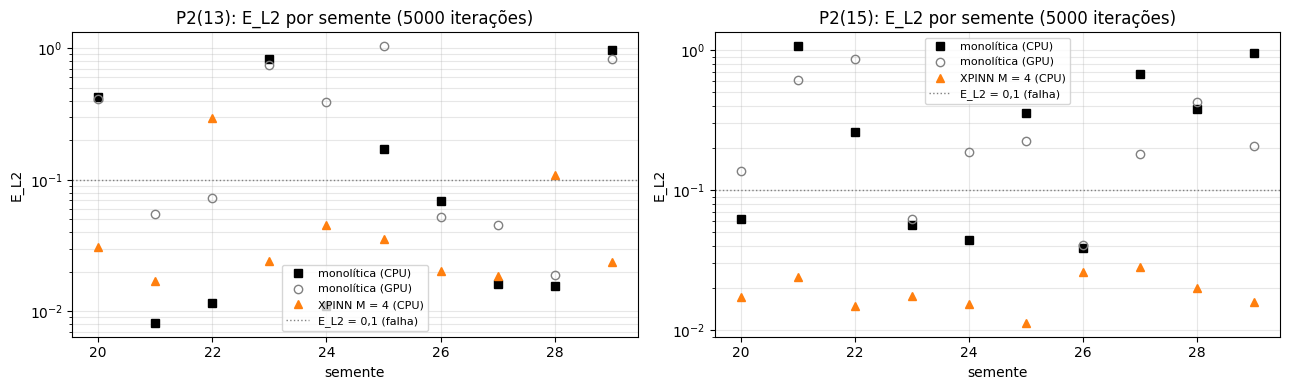

In [16]:
print(f"{'n':>3} {'comparação':>26} {'HL':>7} {'XPINN pior':>11} {'Wilcoxon p':>11} {'desfecho':>26} {'falhas mono/XPINN':>18}")
for n in (13, 15):
    xp = sel("h2_confirmatorio", n=n, M=4)
    for rot, dispositivo in [("monolítica (CPU)", "cpu"), ("monolítica (GPU)", "cuda")]:
        mono = sel("h2_confirmatorio", n=n, dispositivo=dispositivo, M=None)
        k = comparar_razao(met(xp), met(mono))
        d = desfecho_h2(k["p_wilcoxon"], np.log10(k["hodges_lehmann"]), alfa=0.025)
        print(f"{n:>3} {'XPINN / ' + rot:>26} {k['hodges_lehmann']:7.3f} {k['pior_em']:>8} de {k['n']} {k['p_wilcoxon']:11.3g} "
              f"{d:>26} {sum(falha(r['metricas']) for r in mono):>10} / {sum(falha(r['metricas']) for r in xp)}")

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sementes = list(range(20, 30))
for a, n in zip(ax, (13, 15)):
    a.semilogy(sementes, met(sel("h2_confirmatorio", n=n, dispositivo="cpu", M=None)), "s", color="k", label="monolítica (CPU)")
    a.semilogy(sementes, met(sel("h2_confirmatorio", n=n, dispositivo="cuda")), "o", mfc="none", color="gray", label="monolítica (GPU)")
    a.semilogy(sementes, met(sel("h2_confirmatorio", n=n, M=4)), "^", color="tab:orange", label="XPINN M = 4 (CPU)")
    a.axhline(0.1, color="gray", ls=":", lw=1, label="E_L2 = 0,1 (falha)")
    a.set(title=f"P2({n}): E_L2 por semente (5000 iterações)", xlabel="semente", ylabel="E_L2")
    a.grid(True, which="both", alpha=.3)
    a.legend(fontsize=8)
plt.tight_layout()
salvar(fig, "h2_confirmatorio")
plt.show()

# 7. RQ2: a interface do XPINN

Saltos na interface ($J_u$ da solução, $J_n$ do fluxo normal) e balanço global $E_{bal}$, com e sem o termo de continuidade do fluxo, em P1. As razões são sem fluxo / com fluxo, pareadas por semente.

In [17]:
chaves = ["L2", "J_u", "J_n", "E_bal"]
print(f"{'M':>2} {'fluxo':>6} " + " ".join(f"{c:>18}" for c in chaves))
for M in (2, 4):
    com, sem = sel("rq2_fluxo", M=M, fluxo=True), sel("rq2_fluxo", M=M, fluxo=False)
    for rot, rs in [("sim", com), ("não", sem)]:
        print(f"{M:>2} {rot:>6} " + " ".join(f"{geo(met(rs, c)):>18}" for c in chaves))
    razoes = [comparar_razao(met(sem, c), met(com, c)) for c in chaves]
    textos = ["{:.2f} (p={:.2g})".format(k["razao"], k["p_wilcoxon"]) for k in razoes]
    print(f"{'':>2} {'razão':>6} " + " ".join(f"{t:>18}" for t in textos))
    print()

print("Saltos na interface no núcleo (com fluxo), média geométrica:")
print(f"{'problema':>8} {'M':>2} {'J_u':>18} {'J_n':>18} {'E_bal XPINN':>18} {'E_bal mono':>18}")
for rot, arqs in nucleo.items():
    for M in (2, 4):
        rs = arqs[f"XPINN M = {M}"]
        print(f"{rot:>8} {M:>2} {geo(met(rs, 'J_u')):>18} {geo(met(rs, 'J_n')):>18} {geo(met(rs, 'E_bal')):>18} "
              f"{geo(met(arqs['monolítica'], 'E_bal')):>18}")

 M  fluxo                 L2                J_u                J_n              E_bal
 2    sim    2.75e-04 ×/ 1.3    8.88e-04 ×/ 1.4    4.07e-04 ×/ 1.3    8.72e-06 ×/ 3.4
 2    não    3.20e-02 ×/ 2.1    7.58e-04 ×/ 1.4    1.03e-01 ×/ 1.5    2.78e-02 ×/ 2.4
    razão   116.71 (p=0.002)      0.85 (p=0.38)   252.73 (p=0.002)  3187.61 (p=0.002)

 4    sim    8.30e-04 ×/ 1.2    2.45e-03 ×/ 1.2    7.27e-04 ×/ 1.2    4.63e-05 ×/ 2.9
 4    não    5.40e-01 ×/ 1.1    5.24e-03 ×/ 1.3    3.82e-01 ×/ 1.1    4.83e-01 ×/ 1.1
    razão   650.04 (p=0.002)     2.14 (p=0.002)   524.77 (p=0.002) 10425.55 (p=0.002)

Saltos na interface no núcleo (com fluxo), média geométrica:
problema  M                J_u                J_n        E_bal XPINN         E_bal mono
      L0  2    1.44e-02 ×/ 1.3    6.35e-03 ×/ 1.3    1.66e-04 ×/ 3.4    3.58e-06 ×/ 3.3
      L0  4    3.52e-01 ×/ 1.1    4.36e-02 ×/ 1.2    6.06e-03 ×/ 1.8    3.58e-06 ×/ 3.3
      P0  2    1.26e-03 ×/ 1.3    4.21e-04 ×/ 1.2    1.50e-05 ×/ 1.9   